In [1]:
import numpy as np
import pandas as pd
from tensorflow import keras
import cv2
import matplotlib.pyplot as plt
import os
import random
from PIL import Image

In [61]:
df= pd.read_csv("train.csv")
base_path='images'

In [62]:
df

,id,url,landmark_id
0,6e158a47eb2ca3f6,https://upload.wikimedia.org/wikipedia/commons...,142820
1,202cd79556f30760,http://upload.wikimedia.org/wikipedia/commons/...,104169
2,3ad87684c99c06e1,http://upload.wikimedia.org/wikipedia/commons/...,37914
3,e7f70e9c61e66af3,https://upload.wikimedia.org/wikipedia/commons...,102140
4,4072182eddd0100e,https://upload.wikimedia.org/wikipedia/commons...,2474
...,...,...,...
4132909,fc0f007893b11ba7,https://upload.wikimedia.org/wikipedia/commons...,172138
4132910,39aad18585867916,https://upload.wikimedia.org/wikipedia/commons...,162860
4132911,fd0725460e4ebbec,https://upload.wikimedia.org/wikipedia/commons...,191243
4132912,73691ae29e24ba19,https://upload.wikimedia.org/wikipedia/commons...,145760


In [4]:
samples= 20000
df= df.loc[df['id'].str.startswith('00', na=False), :]
num_classes= len(df["landmark_id"].unique())
num_data= len(df)

In [5]:
num_classes

13589

In [6]:
num_data

16157

In [7]:
data= pd.DataFrame(df["landmark_id"].value_counts())

data.reset_index(inplace=True)
data.columns=['landmark_id','count']
data.head()

,landmark_id,count
0,138982,47
1,62798,18
2,83144,14
3,171772,13
4,176528,12


In [8]:
data.tail()

,landmark_id,count
13584,62985,1
13585,161066,1
13586,103418,1
13587,200638,1
13588,63972,1


In [9]:
data.columns=['landmark_id','count']

In [10]:
data['count'].describe()

count    13589.000000
mean         1.188976
std          0.727458
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         47.000000
Name: count, dtype: float64

(array([0.0000e+00, 0.0000e+00, 1.1789e+04, 0.0000e+00, 1.3960e+03,
        0.0000e+00, 2.5400e+02, 0.0000e+00, 7.6000e+01, 0.0000e+00,
        3.4000e+01, 0.0000e+00, 2.0000e+01, 0.0000e+00, 9.0000e+00,
        0.0000e+00, 0.0000e+00, 3.0000e+00, 0.0000e+00, 1.0000e+00,
        0.0000e+00, 2.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        1.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00, 1.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.00

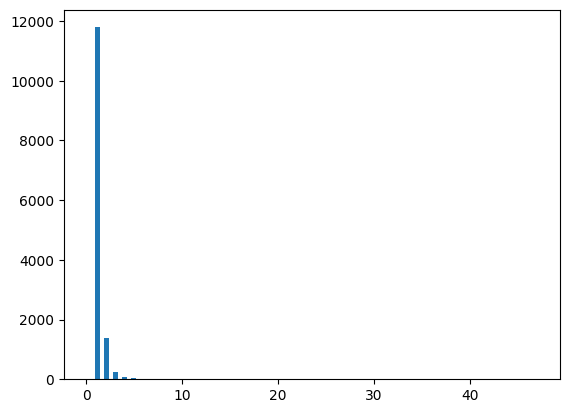

In [11]:
plt.hist(data['count'], 100, range=(0,47), label='test')

In [12]:
from sklearn.preprocessing import LabelEncoder
lencoder= LabelEncoder()
lencoder.fit(df['landmark_id'])

LabelEncoder()

In [13]:
df.head()

,id,url,landmark_id
108,0036d78c05c194d9,https://upload.wikimedia.org/wikipedia/commons...,50089
172,00c08b162f34f53f,https://upload.wikimedia.org/wikipedia/commons...,163404
710,00e5d77c905d94a6,https://upload.wikimedia.org/wikipedia/commons...,26066
1256,00c8dba0df4d112a,https://upload.wikimedia.org/wikipedia/commons...,35744
1262,001cd787f1e9a803,https://upload.wikimedia.org/wikipedia/commons...,61937


In [14]:
def encode_label(lbl):
  return lencoder.transform(lbl)

def decode_label(lbl):
  return lencoder.inverse_transform(lbl)

In [58]:
def get_image_from_number(num,df):
  row = df[num]          
  fname = row[0]        
  label = row[1]
  fname= fname + '.jpg'
  f1= fname[0]
  f2= fname[1]
  f3= fname[2]
  path = os.path.join(base_path, f1, f2, f3, fname)
  im = cv2.imread(path)
  if im is None:
    print("ERROR loading:", path)
  return im, label

4 Sample images from random classes


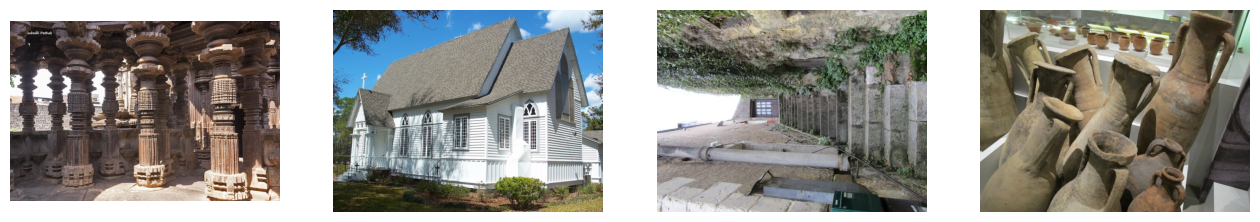

In [16]:
print("4 Sample images from random classes")
fig= plt.figure(figsize=(16,16))
for i in range(1,5):
  ri= random.choices(os.listdir(base_path), k=3)
  folder= base_path+ '/' + ri[0] + '/' + ri[1] + '/' + ri[2]
  random_img= random.choice(os.listdir(folder))
  img= np.array(Image.open(folder+'/'+random_img))
  fig.add_subplot(1,4,i)
  plt.imshow(img)
  plt.axis('off')
plt.show()


In [20]:
import tensorflow as tf
from keras.applications.vgg19 import VGG19
from keras.layers import *
from keras import Sequential
tf.compat.v1.disable_eager_execution()

In [21]:
learning_rate= 0.0001
decay_speed= 1e-6
momentum= 0.09
loss_function= 'sparse_categorical_crossentropy'
source_model= VGG19(weights=None)
drop_layer1= Dropout(0.5)
drop_layer2= Dropout(0.5)

In [23]:
model= Sequential()
for layer in source_model.layers[:-1]:
  if layer== source_model.layers[-25]:
    model.add(BatchNormalization())
  model.add(layer)
model.add(Dense(num_classes, activation='softmax'))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ batch_normalization                  │ (None, 224, 224, 3)         │              12 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv4 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv4 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv4 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,8

 Total params: 195,244,385 (744.80 MB)

 Trainable params: 195,244,379 (744.80 MB)

 Non-trainable params: 6 (24.00 B)

In [26]:
from tensorflow.keras.optimizers import RMSprop
optim1= RMSprop(learning_rate= learning_rate)
model.compile(optimizer=optim1, loss=loss_function, metrics= ['accuracy'])

In [27]:
def image_reshape(im, target_size):
  return cv2.resize(im, target_size)

In [56]:
def get_batch(dataframe, start, batch_size):
  image_array=[]
  label_array=[]

  end_img= start+batch_size
  if (end_img)>len(dataframe):
    end_img=len(dataframe)

  for idx in range(start, end_img):
    n=idx
    im, label= get_image_from_number(n,dataframe)
    im= image_reshape(im, (224,224))/ 255.0
    image_array.append(im)
    label_array.append(label)

  label_array= encode_label(label_array)
  return np.array(image_array), np.array(label_array)

In [46]:
batch_size= 16
epoch_shuffle= True
weight_classes= True
epochs=1

train,val= np.split(df.sample(frac=1),[int(0.8*len(df))])
print(len(train))
print(len(val))

12925
3232


In [64]:
fname = "008e3857625bc84a.jpg"

f1, f2, f3 = fname[0], fname[1], fname[2]
path = os.path.join(f1, f2, f3, fname)

full_path = os.path.join(
    r"C:\Users\Prasenjit\Downloads\google-landmark-master\google-landmark-master\images",
    path
)

print(full_path)
print("Exists:", os.path.exists(full_path))

C:\Users\Prasenjit\Downloads\google-landmark-master\google-landmark-master\images\0\0\8\008e3857625bc84a.jpg
Exists: False


In [63]:
for e in range(epochs):
  print("Epoch :" + str(e+1) + '/' + str(epochs))
  if epoch_shuffle:
    train = train[np.random.permutation(len(train))]
  for it in range(int(np.ceil(len(train)/batch_size))):
    X_train, y_train = get_batch(train, it*batch_size, batch_size)
    model.train_on_batch(X_train, y_train)

model.save("Model")

Epoch :1/1
ERROR loading: images\0\0\8\008e3857625bc84a.jpg


error: OpenCV(4.13.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\resize.cpp:4208: error: (-215:Assertion failed) !ssize.empty() in function 'cv::resize'


In [49]:
batch_size=16

errors=0
good_preds=[]
bad_preds=[]

for it in range(int(np.ceil(len(val)/batch_size))):
  X_train, y_train = get_batch(val, it*batch_size, batch_size)
  result= model.predict(X_val)
  cla= np.argmax(result, axis=1)
  for idx, res in enumerate(result):
    if cla[idx] != y_val[idx]:
      errors= errors + 1
      bad_preds.append([batch_size*it + idx], cla[idx], res[cla[idx]])
    else:
      good_preds.append([batch_size*it + idx], cla[idx], res[cla[idx]])

for i in range(1,6):
  n=int(good_pred[0])
  img, lbl= get_image_from_number(n, val)
  img= cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  plt.imshow(img)

AttributeError: 'numpy.ndarray' object has no attribute 'iloc'